# BlindCore Encrypted Storage Compression Benchmark

**Problem Statement (The Ciphertext Entropy Wall):**  
General-purpose databases such as **PostgreSQL** (`TOAST pglz/lz4`), **MongoDB WiredTiger** (`snappy/zstd`), and **ClickHouse** (`LZ4/ZSTD`) compress *plaintext* workloads effectively. However, the moment an application applies client-side authenticated encryption (**AES-256-GCM**) before writing rows, documents, or columns to a standard database, every stored payload becomes high-entropy pseudorandom noise (~7.999 bits/byte Shannon entropy) plus a 12-byte nonce, 16-byte authentication tag, and database tuple/BSON/block framing. Because uniform random bytes are mathematically incompressible, standard database storage compressors collapse to **<= 1.0x** (net storage **expansion** of `+10%` to `+44%` above raw JSON).

**What This Notebook Measures (100% Live & Reproducible):**
1. Three realistic `10,000`-row developer datasets (`30,000` rows total, deterministic seed `20260401`):
   - **(a) Financial / IoT Numeric Telemetry** (`ts_ns`, `sensor_id`, correlated float64 market & sensor series)
   - **(b) Structured Healthcare / SaaS JSONB Records** (`id`, `ts_ns`, tenant/region/plan/department/status/tags + float64 metrics)
   - **(c) High-Dimensional 4D/6D Spatial Trajectories** (20 vehicle/flight tracks x 500 1-Hz `(t, lat, lon, alt, vx, vy, vz)` waypoints)
2. Exact compressed on-disk / wire byte accounting across five encrypted storage paths:
   - **Uncompressed Raw JSON (NDJSON)** (baseline reference)
   - **PostgreSQL (`BYTEA`/`JSONB` + Client AES-256-GCM + TOAST `pglz`/`lz4`)** (`8 KiB` heap pages, `24 B` HeapTupleHeader, `4 B` line pointer, `MAXALIGN(8)`, real C++ `LZ4` & `zlib` compression check per row)
   - **MongoDB WiredTiger (`BSON` + Client AES-256-GCM + `snappy`/`zstd`)** (exact BSON framing with `BinData` subtype `0x06` Encrypted, `32 KiB` WiredTiger blocks, real C++ `snappy` & `zstd` level 3)
   - **ClickHouse (Columnar + Client AES-256-GCM + `LZ4`/`ZSTD`)** (most-compact single encrypted `String` column, `64 KiB` blocks with `25 B` checksum/header, real C++ `LZ4` & `ZSTD(1)`, plus an **unencrypted plaintext ZSTD control** proving our codecs work)
   - **BlindCore Encrypted Storage (Live Server, Authenticated AES-256-GCM)** (ingesting the exact same NDJSON via `POST /api/v1/ingest`, measuring live wire-sealed encrypted bytes and on-disk AES-256-GCM slab bytes, auditing on-disk Shannon entropy and zero plaintext leakage, and verifying exact SQL aggregate round-trip parity).

Every number in this notebook is computed live from real compression libraries (`pyarrow` C++ `lz4`/`snappy`, `zstandard` C++ `zstd`, OpenSSL `AES-256-GCM`) and a live BlindCore server. Zero synthetic projections or fabricated metrics.

In [1]:
import hashlib
import json
import math
import os
import struct
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyarrow as pa
import zstandard as zstd
from cryptography.hazmat.primitives.ciphers.aead import AESGCM

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.facecolor"] = "white"

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "python" / "blindcore_client.py").is_file():
    REPO_ROOT = REPO_ROOT.parent
assert (REPO_ROOT / "python" / "blindcore_client.py").is_file(), (
    "Run Jupyter from blindcore-eval-kit/ or blindcore-eval-kit/notebooks/"
)
if str(REPO_ROOT / "python") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "python"))

from blindcore_client import BlindCoreClient

BLINDCORE_URL = os.environ["BLINDCORE_URL"].strip()
BLINDCORE_TOKEN = os.environ["BLINDCORE_TOKEN"].strip()
DISK_AUDIT_DIR = os.environ.get("BLINDCORE_DISK_AUDIT_DIR", "").strip()
BENCH_JSON_OUT = os.environ.get("BLINDCORE_BENCH_JSON_OUT", "").strip()

assert BLINDCORE_URL and BLINDCORE_TOKEN, "Set BLINDCORE_URL and BLINDCORE_TOKEN env vars"

client = BlindCoreClient(BLINDCORE_URL, BLINDCORE_TOKEN, timeout=30.0)
cat_status, _, _ = client.request_raw("GET", "/api/v1/catalog")
assert cat_status == 200, f"BlindCore health/catalog check failed with HTTP {cat_status}"

print(f"Connected to BlindCore API (HTTP {cat_status} OK)")
print(f"On-disk ciphertext audit enabled: {bool(DISK_AUDIT_DIR)}")
print(f"Codecs loaded: OpenSSL AES-256-GCM, pyarrow {pa.__version__} (lz4/snappy), zstandard {zstd.__version__}")

Connected to BlindCore API (HTTP 200 OK)
On-disk ciphertext audit enabled: True
Codecs loaded: OpenSSL AES-256-GCM, pyarrow 21.0.0 (lz4/snappy), zstandard 0.23.0


## 1. Deterministic Dataset Generation & Client-Side AES-256-GCM Encryption

We generate `10,000` rows for each of three realistic production workloads using a fixed NumPy PCG64 seed (`20260401`) so every run produces byte-identical inputs:
1. **`fin_iot_telemetry` (Financial / IoT Numeric Telemetry):** Monotonic nanosecond timestamps with microsecond jitter, 16 sensor/market feeds, correlated float64 price/temperature/pressure random walks, volume, and bus voltage.
2. **`saas_health_records` (Structured Healthcare / SaaS JSONB Records):** Sequential record IDs, timestamps, 20 enterprise clinical/SaaS tenants, 6 cloud regions, 4 plan tiers, 8 departments, 4 statuses, compliance tag strings, risk scores, latency, billing amounts, and payload sizes.
3. **`spatial_4d_tracks` (High-Dimensional 4D/6D Spatial Trajectories):** 20 autonomous vehicle/flight tracks with 500 1-Hz waypoints each (`ts_ns`, `track_id`, `lat_deg`, `lon_deg`, `alt_m`, `vx_mps`, `vy_mps`, `vz_mps`).

For the standard-database encrypted baselines, every row's compact UTF-8 JSON representation is encrypted client-side with real **AES-256-GCM** using a unique, uniform 96-bit cryptographic nonce per row (`SHA-256("nonce:<table>:<row>")[:12]`) and table-bound AAD. We verify lossless client-side decryption and confirm that ciphertext Shannon entropy reaches `~7.9999 bits/byte`.

In [2]:
def shannon_entropy_bits(data: bytes) -> float:
    n = len(data)
    if n == 0:
        return 0.0
    counts = Counter(data)
    return -sum((c / n) * math.log2(c / n) for c in counts.values())


N_ROWS = 10_000
RNG_SEED = 20260401
rng = np.random.default_rng(RNG_SEED)
BASE_TS_NS = 1_768_435_200_000_000_000  # 2026-01-15T00:00:00Z

# (a) Financial / IoT Numeric Telemetry
ts_a = BASE_TS_NS + np.arange(N_ROWS, dtype=np.int64) * 100_000_000 + rng.integers(-200_000, 200_000, size=N_ROWS)
sensors = [f"SENSOR-US-{i:02d}" for i in range(16)]
price = 185.0 + np.cumsum(rng.normal(0.0, 0.015, size=N_ROWS))
volume = np.round(np.exp(rng.normal(4.5, 0.35, size=N_ROWS)), 2)
temp_c = 22.4 + np.cumsum(rng.normal(0.0, 0.005, size=N_ROWS))
press_kpa = 101.32 + np.cumsum(rng.normal(0.0, 0.002, size=N_ROWS))
volt_v = 48.0 + rng.normal(0.0, 0.02, size=N_ROWS)

rows_a = [
    {
        "ts_ns": int(ts_a[i]),
        "sensor_id": sensors[i % len(sensors)],
        "price_usd": round(float(price[i]), 4),
        "volume": float(volume[i]),
        "temp_c": round(float(temp_c[i]), 4),
        "pressure_kpa": round(float(press_kpa[i]), 4),
        "voltage_v": round(float(volt_v[i]), 4),
    }
    for i in range(N_ROWS)
]

# (b) Structured Healthcare / SaaS JSONB Records
tenants = [f"org_clinical_{i:02d}" for i in range(20)]
regions = ["us-east-1", "us-west-2", "eu-central-1", "eu-west-1", "ap-northeast-1", "us-gov-east-1"]
plans = ["enterprise", "clinical", "business", "starter"]
depts = ["cardiology", "oncology", "radiology", "billing", "auth_api", "claims", "pharmacy", "triage"]
statuses = ["active", "verified", "pending", "flagged"]
tag_sets = [
    "hipaa,phi,tier1",
    "hipaa,phi,audit,tier1",
    "soc2,saas,telemetry",
    "hipaa,claims,encrypted",
    "gdpr,eu,clinical",
    "fedramp,audit,strict",
]
ts_b = BASE_TS_NS + np.arange(N_ROWS, dtype=np.int64) * 1_000_000_000 + rng.integers(0, 500_000, size=N_ROWS)
risk = np.round(rng.beta(2.0, 8.0, size=N_ROWS), 4)
lat_ms = np.round(rng.lognormal(2.5, 0.45, size=N_ROWS), 2)
billing = np.round(rng.choice([49.0, 199.0, 499.0, 1250.0, 2499.0], size=N_ROWS) + rng.uniform(0.0, 25.0, size=N_ROWS), 2)
payload_b = rng.integers(256, 4096, size=N_ROWS)

rows_b = [
    {
        "id": i + 1,
        "ts_ns": int(ts_b[i]),
        "tenant_id": tenants[int(rng.integers(0, len(tenants)))],
        "region": regions[int(rng.integers(0, len(regions)))],
        "plan_tier": plans[int(rng.integers(0, len(plans)))],
        "department": depts[int(rng.integers(0, len(depts)))],
        "status": statuses[int(rng.integers(0, len(statuses)))],
        "tags": tag_sets[int(rng.integers(0, len(tag_sets)))],
        "risk_score": float(risk[i]),
        "latency_ms": float(lat_ms[i]),
        "billing_usd": float(billing[i]),
        "payload_bytes": int(payload_b[i]),
    }
    for i in range(N_ROWS)
]

# (c) High-Dimensional 4D/6D Spatial Trajectories
rows_c = []
for tid in range(20):
    t_lat = 37.70 + 0.01 * tid
    t_lon = -122.45 + 0.01 * tid
    t_alt = 150.0 + 25.0 * tid
    vx = float(rng.uniform(12.0, 24.0))
    vy = float(rng.uniform(-8.0, 8.0))
    vz = float(rng.uniform(-0.5, 0.5))
    for step in range(N_ROWS // 20):
        vx += float(rng.normal(0.0, 0.05))
        vy += float(rng.normal(0.0, 0.05))
        vz += float(rng.normal(0.0, 0.01))
        t_lat += vy * 1e-5
        t_lon += vx * 1e-5
        t_alt += vz
        rows_c.append({
            "ts_ns": int(BASE_TS_NS + (tid * (N_ROWS // 20) + step) * 1_000_000_000),
            "track_id": f"TRK-{tid + 1:03d}",
            "lat_deg": round(t_lat, 6),
            "lon_deg": round(t_lon, 6),
            "alt_m": round(t_alt, 3),
            "vx_mps": round(vx, 4),
            "vy_mps": round(vy, 4),
            "vz_mps": round(vz, 4),
        })

DATASETS = [
    {
        "key": "fin_iot_telemetry",
        "table": "bench_a_fin_iot",
        "label": "Financial / IoT Telemetry",
        "rows": rows_a,
        "sum_col": "price_usd",
        "probe_tokens": [b"SENSOR-US-00", b"price_usd", b"pressure_kpa"],
    },
    {
        "key": "saas_health_records",
        "table": "bench_b_saas_health",
        "label": "Healthcare / SaaS JSONB",
        "rows": rows_b,
        "sum_col": "billing_usd",
        "probe_tokens": [b"org_clinical_00", b"cardiology", b"hipaa,phi"],
    },
    {
        "key": "spatial_4d_tracks",
        "table": "bench_c_spatial_4d",
        "label": "4D/6D Spatial Trajectories",
        "rows": rows_c,
        "sum_col": "alt_m",
        "probe_tokens": [b"TRK-001", b"lat_deg", b"vx_mps"],
    },
]

client_aes_key = hashlib.sha256(b"blindcore-bench-client-aes256-key-2026").digest()
client_aes = AESGCM(client_aes_key)

for ds in DATASETS:
    row_jsons = [json.dumps(r, separators=(",", ":")).encode("utf-8") for r in ds["rows"]]
    ndjson = b"\n".join(row_jsons) + b"\n"
    aad = ds["key"].encode("ascii")
    ciphertexts = []
    for i, rj in enumerate(row_jsons):
        nonce = hashlib.sha256(f"nonce:{ds['key']}:{i}".encode("ascii")).digest()[:12]
        ct = nonce + client_aes.encrypt(nonce, rj, aad)
        ciphertexts.append(ct)
    # Verify exact AES-256-GCM decryption round-trip on first and last row
    for check_i in (0, N_ROWS - 1):
        c = ciphertexts[check_i]
        pt = client_aes.decrypt(c[:12], c[12:], aad)
        assert pt == row_jsons[check_i], "AES-256-GCM round-trip mismatch"
    ds["row_jsons"] = row_jsons
    ds["ndjson"] = ndjson
    ds["raw_json_bytes"] = len(ndjson)
    ds["ciphertexts"] = ciphertexts
    ds["raw_ciphertext_bytes"] = sum(len(c) for c in ciphertexts)
    ds["ciphertext_entropy_bits"] = shannon_entropy_bits(b"".join(ciphertexts))
    ds["expected_sum"] = float(sum(r[ds["sum_col"]] for r in ds["rows"]))
    print(
        f"{ds['label']:<28} | rows={N_ROWS:,} | raw_json={ds['raw_json_bytes']:>10,} B "
        f"| aes_gcm={ds['raw_ciphertext_bytes']:>10,} B | entropy={ds['ciphertext_entropy_bits']:.4f} bits/B"
    )

Financial / IoT Telemetry    | rows=10,000 | raw_json= 1,538,475 B | aes_gcm= 1,808,475 B | entropy=7.9999 bits/B
Healthcare / SaaS JSONB      | rows=10,000 | raw_json= 2,681,129 B | aes_gcm= 2,951,129 B | entropy=7.9999 bits/B


4D/6D Spatial Trajectories   | rows=10,000 | raw_json= 1,580,307 B | aes_gcm= 1,850,307 B | entropy=7.9999 bits/B


## 2. Standard Database Storage Baselines on Encrypted Payloads

To keep the comparison maximally conservative and fair to PostgreSQL, MongoDB, and ClickHouse, we count **pure table/collection data storage only** (excluding B-tree indexes, secondary indexes, and WAL overhead):

- **PostgreSQL (`BYTEA`/`JSONB` + Client AES-256-GCM + TOAST `pglz`/`lz4`):**
  - Exact 64-bit PostgreSQL heap layout: `8,192 B` pages (`24 B` `PageHeaderData`), `24 B` `HeapTupleHeaderData`, `1 B` or `4 B` `varlena` header, `MAXALIGN(8)` tuple alignment, and `4 B` `ItemIdData` line pointer per row.
  - Every row's AES-256-GCM ciphertext is tested against real C++ `LZ4` (PG 14+ default TOAST compressor) and `zlib` (LZ77/`pglz` check). Whenever compression fails to shrink the value, PostgreSQL stores the raw ciphertext uncompressed.
- **MongoDB WiredTiger (`BSON` + Client AES-256-GCM + `snappy`/`zstd`):**
  - Exact BSON document layout matching CSFLE / application-encrypted documents: `4 B` doc length + `17 B` `_id` (`ObjectId`) + `BinData` field (`subtype 0x06` Encrypted) + `1 B` null terminator.
  - Packed into `32 KiB` WiredTiger leaf blocks (`64 B` page+block header) and compressed with real C++ `snappy` (WiredTiger default) and `zstd` level 3.
- **ClickHouse (Columnar + Client AES-256-GCM + `LZ4`/`ZSTD`):**
  - Most-compact client-encrypted columnar layout: one encrypted `String` column per row (`LEB128` length prefix + ciphertext), avoiding the `28 B/cell` nonce+tag explosion of encrypting every numeric column separately.
  - Packed into `64 KiB` ClickHouse blocks (`25 B` CityHash128 checksum + header) and compressed with real C++ `LZ4` and `ZSTD(1)`.
  - We also run an **Unencrypted Plaintext ClickHouse `ZSTD(1)` Control** on the raw NDJSON to verify that our `ZSTD` codec achieves `6.4x - 7.2x` compression on plaintext and collapses to `< 1.0x` strictly due to AES-256-GCM ciphertext entropy.

In [3]:
import zlib


def encode_varint(n: int) -> bytes:
    out = bytearray()
    while True:
        b = n & 0x7F
        n >>= 7
        if n:
            out.append(b | 0x80)
        else:
            out.append(b)
            break
    return bytes(out)


def bench_postgres_encrypted(ciphertexts: list[bytes]) -> dict:
    PAGE_SIZE = 8192
    PAGE_HEADER = 24
    ITEM_ID_LEN = 4
    TUPLE_HEADER = 24
    lz4_shrunk = 0
    zlib_shrunk = 0
    pages = 1
    used = PAGE_HEADER
    for ct in ciphertexts:
        c_lz4 = pa.compress(ct, codec="lz4", asbytes=True)
        c_zlib = zlib.compress(ct, level=1)
        if len(c_lz4) < len(ct):
            lz4_shrunk += 1
        if len(c_zlib) < len(ct):
            zlib_shrunk += 1
        stored = c_lz4 if len(c_lz4) < len(ct) else ct
        varlena_hdr = 1 if (len(stored) + 1) < 128 else 4
        tuple_len = ((TUPLE_HEADER + varlena_hdr + len(stored) + 7) // 8) * 8
        needed = tuple_len + ITEM_ID_LEN
        if used + needed > PAGE_SIZE:
            pages += 1
            used = PAGE_HEADER + needed
        else:
            used += needed
    return {
        "total_bytes": pages * PAGE_SIZE,
        "pages": pages,
        "lz4_rows_compressed": lz4_shrunk,
        "pglz_check_rows_compressed": zlib_shrunk,
    }


def bench_mongodb_wiredtiger_encrypted(ciphertexts: list[bytes]) -> dict:
    WT_PAGE_SIZE = 32_768
    WT_OVERHEAD = 64  # 40 B page header + 24 B block header
    zstd_c = zstd.ZstdCompressor(level=3)
    bson_stream = bytearray()
    for i, ct in enumerate(ciphertexts):
        # BSON: 4B len + 17B _id(ObjectId) + 1B(0x05) + "ct\0" + 4B len + 1B(0x06) + ct + 1B null
        doc_len = 4 + 17 + 1 + 3 + 4 + 1 + len(ct) + 1
        bson_stream += struct.pack("<I", doc_len)
        bson_stream += b"\x07_id\x00" + struct.pack(">II", 0x69682000, i) + b"\x00\x00\x00\x00"
        bson_stream += b"\x05ct\x00" + struct.pack("<I", len(ct)) + b"\x06" + ct + b"\x00"

    raw_bson_bytes = len(bson_stream)
    snappy_total = 0
    zstd_total = 0
    snappy_shrunk = 0
    zstd_shrunk = 0
    blocks = 0
    for off in range(0, raw_bson_bytes, WT_PAGE_SIZE):
        blk = bytes(bson_stream[off : off + WT_PAGE_SIZE])
        blocks += 1
        s_comp = pa.compress(blk, codec="snappy", asbytes=True)
        z_comp = zstd_c.compress(blk)
        if len(s_comp) < len(blk):
            snappy_shrunk += 1
            snappy_total += len(s_comp) + WT_OVERHEAD
        else:
            snappy_total += len(blk) + WT_OVERHEAD
        if len(z_comp) < len(blk):
            zstd_shrunk += 1
            zstd_total += len(z_comp) + WT_OVERHEAD
        else:
            zstd_total += len(blk) + WT_OVERHEAD
    return {
        "raw_bson_bytes": raw_bson_bytes,
        "blocks": blocks,
        "snappy_bytes": snappy_total,
        "zstd_bytes": zstd_total,
        "snappy_blocks_compressed": snappy_shrunk,
        "zstd_blocks_compressed": zstd_shrunk,
    }


def bench_clickhouse_encrypted(ciphertexts: list[bytes], raw_ndjson: bytes) -> dict:
    CH_BLOCK_SIZE = 65_536
    CH_OVERHEAD = 25  # 16 B CityHash128 checksum + 9 B compression header
    zstd_c = zstd.ZstdCompressor(level=1)
    col_stream = bytearray()
    for ct in ciphertexts:
        col_stream += encode_varint(len(ct)) + ct

    lz4_total = 0
    zstd_total = 0
    lz4_shrunk = 0
    zstd_shrunk = 0
    blocks = 0
    for off in range(0, len(col_stream), CH_BLOCK_SIZE):
        blk = bytes(col_stream[off : off + CH_BLOCK_SIZE])
        blocks += 1
        l_comp = pa.compress(blk, codec="lz4", asbytes=True)
        z_comp = zstd_c.compress(blk)
        if len(l_comp) < len(blk):
            lz4_shrunk += 1
            lz4_total += len(l_comp) + CH_OVERHEAD
        else:
            lz4_total += len(blk) + CH_OVERHEAD
        if len(z_comp) < len(blk):
            zstd_shrunk += 1
            zstd_total += len(z_comp) + CH_OVERHEAD
        else:
            zstd_total += len(blk) + CH_OVERHEAD

    # Control: ClickHouse ZSTD(1) on unencrypted plaintext NDJSON
    plain_zstd = 0
    for off in range(0, len(raw_ndjson), CH_BLOCK_SIZE):
        blk = raw_ndjson[off : off + CH_BLOCK_SIZE]
        plain_zstd += min(len(blk), len(zstd_c.compress(blk))) + CH_OVERHEAD

    return {
        "blocks": blocks,
        "lz4_bytes": lz4_total,
        "zstd_bytes": zstd_total,
        "lz4_blocks_compressed": lz4_shrunk,
        "zstd_blocks_compressed": zstd_shrunk,
        "plaintext_zstd_control_bytes": plain_zstd,
    }


for ds in DATASETS:
    ds["postgres"] = bench_postgres_encrypted(ds["ciphertexts"])
    ds["mongodb"] = bench_mongodb_wiredtiger_encrypted(ds["ciphertexts"])
    ds["clickhouse"] = bench_clickhouse_encrypted(ds["ciphertexts"], ds["ndjson"])
    raw = ds["raw_json_bytes"]
    pg = ds["postgres"]
    mg = ds["mongodb"]
    ch = ds["clickhouse"]
    print(f"=== {ds['label']} (raw_json = {raw:,} B) ===")
    print(
        f"  PostgreSQL (AES-GCM + TOAST LZ4)   : {pg['total_bytes']:>10,} B "
        f"({raw / pg['total_bytes']:.2f}x) | rows compressed by LZ4: {pg['lz4_rows_compressed']}/{N_ROWS}"
    )
    print(
        f"  MongoDB WT (AES-GCM + Snappy)      : {mg['snappy_bytes']:>10,} B "
        f"({raw / mg['snappy_bytes']:.2f}x) | blocks compressed: {mg['snappy_blocks_compressed']}/{mg['blocks']}"
    )
    print(
        f"  MongoDB WT (AES-GCM + ZSTD)        : {mg['zstd_bytes']:>10,} B "
        f"({raw / mg['zstd_bytes']:.2f}x) | blocks compressed: {mg['zstd_blocks_compressed']}/{mg['blocks']}"
    )
    print(
        f"  ClickHouse (AES-GCM + LZ4)         : {ch['lz4_bytes']:>10,} B "
        f"({raw / ch['lz4_bytes']:.2f}x) | blocks compressed: {ch['lz4_blocks_compressed']}/{ch['blocks']}"
    )
    print(
        f"  ClickHouse (AES-GCM + ZSTD)        : {ch['zstd_bytes']:>10,} B "
        f"({raw / ch['zstd_bytes']:.2f}x) | blocks compressed: {ch['zstd_blocks_compressed']}/{ch['blocks']}"
    )
    print(
        f"  [Control] ClickHouse Plaintext ZSTD: {ch['plaintext_zstd_control_bytes']:>10,} B "
        f"({raw / ch['plaintext_zstd_control_bytes']:.2f}x)"
    )

=== Financial / IoT Telemetry (raw_json = 1,538,475 B) ===
  PostgreSQL (AES-GCM + TOAST LZ4)   :  2,220,032 B (0.69x) | rows compressed by LZ4: 0/10000
  MongoDB WT (AES-GCM + Snappy)      :  1,954,666 B (0.79x) | blocks compressed: 65/65
  MongoDB WT (AES-GCM + ZSTD)        :  1,855,297 B (0.83x) | blocks compressed: 65/65
  ClickHouse (AES-GCM + LZ4)         :  1,829,175 B (0.84x) | blocks compressed: 0/28
  ClickHouse (AES-GCM + ZSTD)        :  1,829,175 B (0.84x) | blocks compressed: 0/28
  [Control] ClickHouse Plaintext ZSTD:    238,052 B (6.46x)


=== Healthcare / SaaS JSONB (raw_json = 2,681,129 B) ===
  PostgreSQL (AES-GCM + TOAST LZ4)   :  3,416,064 B (0.78x) | rows compressed by LZ4: 0/10000
  MongoDB WT (AES-GCM + Snappy)      :  3,177,837 B (0.84x) | blocks compressed: 94/100
  MongoDB WT (AES-GCM + ZSTD)        :  3,025,482 B (0.89x) | blocks compressed: 100/100
  ClickHouse (AES-GCM + LZ4)         :  2,972,279 B (0.90x) | blocks compressed: 0/46
  ClickHouse (AES-GCM + ZSTD)        :  2,972,279 B (0.90x) | blocks compressed: 0/46
  [Control] ClickHouse Plaintext ZSTD:    374,572 B (7.16x)


=== 4D/6D Spatial Trajectories (raw_json = 1,580,307 B) ===
  PostgreSQL (AES-GCM + TOAST LZ4)   :  2,220,032 B (0.71x) | rows compressed by LZ4: 0/10000
  MongoDB WT (AES-GCM + Snappy)      :  2,006,702 B (0.79x) | blocks compressed: 66/66
  MongoDB WT (AES-GCM + ZSTD)        :  1,896,274 B (0.83x) | blocks compressed: 66/66
  ClickHouse (AES-GCM + LZ4)         :  1,871,032 B (0.84x) | blocks compressed: 0/29
  ClickHouse (AES-GCM + ZSTD)        :  1,871,032 B (0.84x) | blocks compressed: 0/29
  [Control] ClickHouse Plaintext ZSTD:    238,667 B (6.62x)


## 3. Live BlindCore Encrypted Storage Benchmark & On-Disk Ciphertext Audit

Now we ingest the exact same three `10,000`-row NDJSON datasets into our live **BlindCore** server via `POST /api/v1/ingest?table=<table>&format=json`:
1. **Wire-Sealed Encrypted Storage Frame:** The server returns the exact compressed binary payload size (`bytes`). Adding the fixed `64 B` authenticated AES-256-GCM envelope (`48 B` header + `16 B` authentication tag) yields the exact encrypted wire-frame size.
2. **On-Disk Encrypted Storage (Primary Metric):** When `BLINDCORE_DISK_AUDIT_DIR` is attached to a local BlindCore server running with 256-bit AES-256-GCM disk encryption, we trigger a memtable flush and measure the **exact on-disk encrypted storage file size** for each dataset -- which ALREADY includes built-in column indexes, probabilistic membership filters, dual-clock audit columns, and the authenticated AES-256-GCM envelope.
3. **Zero-Plaintext & High-Entropy Disk Audit:** We scan the raw on-disk encrypted files to verify `0` plaintext token leaks and Shannon ciphertext entropy `> 7.99 bits/byte`.
4. **Exact SQL Round-Trip Verification:** After flushing to encrypted disk storage, we execute live SQL `SELECT COUNT(*), SUM(<metric>)` queries via `POST /api/v1/query?format=json` and assert exact parity with the NumPy/Python ground truth.

In [4]:
AEAD_ENVELOPE_BYTES = 64  # 48 B authenticated header + 16 B AES-256-GCM tag

for ds in DATASETS:
    t0 = time.perf_counter()
    st, _, body = client.request_raw(
        "POST",
        f"/api/v1/ingest?table={ds['table']}&format=json",
        body=ds["ndjson"],
        content_type="application/x-ndjson",
    )
    ingest_ms = (time.perf_counter() - t0) * 1000.0
    assert st == 200, f"Ingest failed for {ds['table']}: HTTP {st} {body.decode('utf-8', 'replace')}"
    res = json.loads(body.decode("utf-8"))
    assert int(res["rows"]) == N_ROWS, f"Expected {N_ROWS} ingested rows, got {res['rows']}"
    wire_enc_bytes = int(res["bytes"]) + AEAD_ENVELOPE_BYTES
    ds["blindcore"] = {
        "ingest_ms": round(ingest_ms, 2),
        "wire_encrypted_bytes": wire_enc_bytes,
        "disk_encrypted_bytes": None,
        "disk_entropy_bits": None,
        "disk_plaintext_leaks": None,
    }

# If auditing a local encrypted BlindCore data directory, flush memtable to encrypted disk slabs
if DISK_AUDIT_DIR:
    flush_rows = ("\n".join(f'{{"id":{i}}}' for i in range(36_000)) + "\n").encode("utf-8")
    st_f, _, body_f = client.request_raw(
        "POST",
        "/api/v1/ingest?table=z_flush_trigger&format=json",
        body=flush_rows,
        content_type="application/x-ndjson",
    )
    assert st_f == 200, f"Flush trigger failed: HTTP {st_f} {body_f.decode('utf-8', 'replace')}"
    time.sleep(0.2)

    slab_dir = Path(DISK_AUDIT_DIR) / "slabs" / "0s"
    slab_files = sorted(
        (p for p in slab_dir.iterdir() if p.is_file() and p.name.startswith("slab_")),
        key=lambda p: int(p.stem.split("_")[1]),
    )
    assert len(slab_files) >= len(DATASETS), f"Expected >= {len(DATASETS)} flushed encrypted files, found {len(slab_files)}"

    for ds, slab_path in zip(DATASETS, slab_files[: len(DATASETS)]):
        raw_disk = slab_path.read_bytes()
        ct_body = raw_disk[48:-16]
        ent = shannon_entropy_bits(ct_body)
        leaks = sum(1 for tok in ds["probe_tokens"] if tok in raw_disk)
        assert leaks == 0, f"Plaintext leak detected on disk for {ds['key']}!"
        assert ent > 7.99, f"Expected encrypted ciphertext entropy > 7.99 bits/B, got {ent:.4f}"
        ds["blindcore"]["disk_encrypted_bytes"] = len(raw_disk)
        ds["blindcore"]["disk_entropy_bits"] = round(ent, 4)
        ds["blindcore"]["disk_plaintext_leaks"] = leaks

# Verify exact SQL round-trip queries AFTER flush to encrypted disk storage
for ds in DATASETS:
    q = f"SELECT COUNT(*), SUM({ds['sum_col']}) FROM {ds['table']}"
    t0 = time.perf_counter()
    qres = client.query_json(q)
    q_ms = (time.perf_counter() - t0) * 1000.0
    got_cnt, got_sum = qres["rows"][0]
    assert int(got_cnt) == N_ROWS, f"SQL COUNT mismatch: {got_cnt} != {N_ROWS}"
    rel_err = abs(float(got_sum) - ds["expected_sum"]) / max(abs(ds["expected_sum"]), 1.0)
    assert rel_err < 1e-9, f"SQL SUM mismatch for {ds['key']}: got {got_sum}, expected {ds['expected_sum']}"
    ds["blindcore"]["query_ms"] = round(q_ms, 2)
    ds["blindcore"]["sql_count"] = int(got_cnt)
    ds["blindcore"]["sql_sum"] = float(got_sum)

    bc = ds["blindcore"]
    primary_b = bc["disk_encrypted_bytes"] or bc["wire_encrypted_bytes"]
    raw = ds["raw_json_bytes"]
    print(f"=== {ds['label']} ===")
    print(
        f"  BlindCore On-Disk Encrypted (AES-256-GCM): {primary_b:>10,} B "
        f"({raw / primary_b:.2f}x vs raw JSON) | entropy={bc['disk_entropy_bits']} bits/B | leaks={bc['disk_plaintext_leaks']}"
    )
    print(
        f"  BlindCore Wire-Sealed Encrypted Frame    : {bc['wire_encrypted_bytes']:>10,} B "
        f"({raw / bc['wire_encrypted_bytes']:.2f}x vs raw JSON) | ingest={bc['ingest_ms']:.1f} ms"
    )
    print(
        f"  SQL Round-Trip Parity ({ds['sum_col']:<11})    : COUNT={got_cnt:,}, "
        f"SUM={float(got_sum):.3f} (exact match, {q_ms:.2f} ms)"
    )

=== Financial / IoT Telemetry ===
  BlindCore On-Disk Encrypted (AES-256-GCM):    230,312 B (6.68x vs raw JSON) | entropy=7.9992 bits/B | leaks=0
  BlindCore Wire-Sealed Encrypted Frame    :    130,992 B (11.74x vs raw JSON) | ingest=30.4 ms
  SQL Round-Trip Parity (price_usd  )    : COUNT=10,000, SUM=1855737.871 (exact match, 3.18 ms)
=== Healthcare / SaaS JSONB ===
  BlindCore On-Disk Encrypted (AES-256-GCM):    211,368 B (12.68x vs raw JSON) | entropy=7.9991 bits/B | leaks=0
  BlindCore Wire-Sealed Encrypted Frame    :    176,120 B (15.22x vs raw JSON) | ingest=68.5 ms
  SQL Round-Trip Parity (billing_usd)    : COUNT=10,000, SUM=8908763.510 (exact match, 6.55 ms)
=== 4D/6D Spatial Trajectories ===
  BlindCore On-Disk Encrypted (AES-256-GCM):    236,000 B (6.70x vs raw JSON) | entropy=7.9991 bits/B | leaks=0
  BlindCore Wire-Sealed Encrypted Frame    :    129,200 B (12.23x vs raw JSON) | ingest=23.3 ms
  SQL Round-Trip Parity (alt_m      )    : COUNT=10,000, SUM=4046333.325 (exact ma

## 4. Verified Comparison Table & Storage Savings Summary

Below is the exact measured comparison across all three `10,000`-row datasets (`30,000` rows combined). All ratios compare **on-disk encrypted storage** (using BlindCore's full on-disk AES-256-GCM storage file, including built-in indexes and dual-clock metadata) against PostgreSQL (`BYTEA` + AES-256-GCM + TOAST `LZ4`), MongoDB WiredTiger (`BSON` + AES-256-GCM + `ZSTD`/`Snappy`), and ClickHouse (`Columnar` + AES-256-GCM + `ZSTD`/`LZ4`).

In [5]:
def fmt_kb(n_bytes: int) -> str:
    return f"{n_bytes / 1024.0:,.1f} KiB"


def fmt_mb(n_bytes: int) -> str:
    return f"{n_bytes / (1024.0 * 1024.0):.2f} MiB"


summary_rows = []
totals = {
    "rows": 0,
    "raw_json_bytes": 0,
    "postgres_aes_lz4_bytes": 0,
    "mongodb_aes_snappy_bytes": 0,
    "mongodb_aes_zstd_bytes": 0,
    "clickhouse_aes_lz4_bytes": 0,
    "clickhouse_aes_zstd_bytes": 0,
    "clickhouse_plaintext_zstd_bytes": 0,
    "blindcore_disk_encrypted_bytes": 0,
    "blindcore_wire_encrypted_bytes": 0,
}

for ds in DATASETS:
    bc = ds["blindcore"]
    bc_disk = bc["disk_encrypted_bytes"] or bc["wire_encrypted_bytes"]
    bc_wire = bc["wire_encrypted_bytes"]
    raw = ds["raw_json_bytes"]
    pg = ds["postgres"]["total_bytes"]
    mg_sn = ds["mongodb"]["snappy_bytes"]
    mg_zs = ds["mongodb"]["zstd_bytes"]
    ch_l4 = ds["clickhouse"]["lz4_bytes"]
    ch_zs = ds["clickhouse"]["zstd_bytes"]
    ch_pt = ds["clickhouse"]["plaintext_zstd_control_bytes"]

    rec = {
        "key": ds["key"],
        "label": ds["label"],
        "rows": N_ROWS,
        "raw_json_bytes": raw,
        "client_aes_gcm_entropy_bits": round(ds["ciphertext_entropy_bits"], 4),
        "postgres_aes_lz4_bytes": pg,
        "postgres_ratio_vs_raw": round(raw / pg, 2),
        "mongodb_aes_snappy_bytes": mg_sn,
        "mongodb_aes_zstd_bytes": mg_zs,
        "mongodb_zstd_ratio_vs_raw": round(raw / mg_zs, 2),
        "clickhouse_aes_lz4_bytes": ch_l4,
        "clickhouse_aes_zstd_bytes": ch_zs,
        "clickhouse_zstd_ratio_vs_raw": round(raw / ch_zs, 2),
        "clickhouse_plaintext_zstd_bytes": ch_pt,
        "clickhouse_plaintext_ratio_vs_raw": round(raw / ch_pt, 2),
        "blindcore_disk_encrypted_bytes": bc_disk,
        "blindcore_wire_encrypted_bytes": bc_wire,
        "blindcore_disk_ratio_vs_raw": round(raw / bc_disk, 2),
        "blindcore_wire_ratio_vs_raw": round(raw / bc_wire, 2),
        "blindcore_disk_entropy_bits": bc["disk_entropy_bits"],
        "blindcore_disk_plaintext_leaks": bc["disk_plaintext_leaks"],
        "blindcore_vs_postgres_x": round(pg / bc_disk, 2),
        "blindcore_vs_mongodb_zstd_x": round(mg_zs / bc_disk, 2),
        "blindcore_vs_clickhouse_zstd_x": round(ch_zs / bc_disk, 2),
        "savings_vs_postgres_pct": round((1.0 - bc_disk / pg) * 100.0, 1),
        "savings_vs_mongodb_zstd_pct": round((1.0 - bc_disk / mg_zs) * 100.0, 1),
        "savings_vs_clickhouse_zstd_pct": round((1.0 - bc_disk / ch_zs) * 100.0, 1),
        "ingest_ms": bc["ingest_ms"],
        "query_ms": bc["query_ms"],
    }
    summary_rows.append(rec)
    totals["rows"] += N_ROWS
    totals["raw_json_bytes"] += raw
    totals["postgres_aes_lz4_bytes"] += pg
    totals["mongodb_aes_snappy_bytes"] += mg_sn
    totals["mongodb_aes_zstd_bytes"] += mg_zs
    totals["clickhouse_aes_lz4_bytes"] += ch_l4
    totals["clickhouse_aes_zstd_bytes"] += ch_zs
    totals["clickhouse_plaintext_zstd_bytes"] += ch_pt
    totals["blindcore_disk_encrypted_bytes"] += bc_disk
    totals["blindcore_wire_encrypted_bytes"] += bc_wire

tot_bc = totals["blindcore_disk_encrypted_bytes"]
tot_raw = totals["raw_json_bytes"]
totals["postgres_ratio_vs_raw"] = round(tot_raw / totals["postgres_aes_lz4_bytes"], 2)
totals["mongodb_zstd_ratio_vs_raw"] = round(tot_raw / totals["mongodb_aes_zstd_bytes"], 2)
totals["clickhouse_zstd_ratio_vs_raw"] = round(tot_raw / totals["clickhouse_aes_zstd_bytes"], 2)
totals["clickhouse_plaintext_ratio_vs_raw"] = round(tot_raw / totals["clickhouse_plaintext_zstd_bytes"], 2)
totals["blindcore_disk_ratio_vs_raw"] = round(tot_raw / tot_bc, 2)
totals["blindcore_wire_ratio_vs_raw"] = round(tot_raw / totals["blindcore_wire_encrypted_bytes"], 2)
totals["blindcore_vs_postgres_x"] = round(totals["postgres_aes_lz4_bytes"] / tot_bc, 2)
totals["blindcore_vs_mongodb_zstd_x"] = round(totals["mongodb_aes_zstd_bytes"] / tot_bc, 2)
totals["blindcore_vs_clickhouse_zstd_x"] = round(totals["clickhouse_aes_zstd_bytes"] / tot_bc, 2)
totals["savings_vs_postgres_pct"] = round((1.0 - tot_bc / totals["postgres_aes_lz4_bytes"]) * 100.0, 1)
totals["savings_vs_mongodb_zstd_pct"] = round((1.0 - tot_bc / totals["mongodb_aes_zstd_bytes"]) * 100.0, 1)
totals["savings_vs_clickhouse_zstd_pct"] = round((1.0 - tot_bc / totals["clickhouse_aes_zstd_bytes"]) * 100.0, 1)

header = (
    "| Dataset (10,000 rows) | Raw JSON | PostgreSQL (AES-GCM + TOAST LZ4) | "
    "MongoDB WT (AES-GCM + ZSTD) | ClickHouse (AES-GCM + ZSTD) | "
    "BlindCore Encrypted Storage | Savings vs Encrypted DBs |"
)
sep = "| :--- | ---: | ---: | ---: | ---: | ---: | ---: |"
print(header)
print(sep)
for r in summary_rows:
    print(
        f"| {r['label']} | {fmt_kb(r['raw_json_bytes'])} | "
        f"{fmt_kb(r['postgres_aes_lz4_bytes'])} ({r['postgres_ratio_vs_raw']:.2f}x) | "
        f"{fmt_kb(r['mongodb_aes_zstd_bytes'])} ({r['mongodb_zstd_ratio_vs_raw']:.2f}x) | "
        f"{fmt_kb(r['clickhouse_aes_zstd_bytes'])} ({r['clickhouse_zstd_ratio_vs_raw']:.2f}x) | "
        f"**{fmt_kb(r['blindcore_disk_encrypted_bytes'])} ({r['blindcore_disk_ratio_vs_raw']:.2f}x)** | "
        f"**{r['blindcore_vs_clickhouse_zstd_x']:.1f}x - {r['blindcore_vs_postgres_x']:.1f}x smaller** |"
    )
print(
    f"| **Total (30,000 rows)** | **{fmt_mb(totals['raw_json_bytes'])}** | "
    f"**{fmt_mb(totals['postgres_aes_lz4_bytes'])} ({totals['postgres_ratio_vs_raw']:.2f}x)** | "
    f"**{fmt_mb(totals['mongodb_aes_zstd_bytes'])} ({totals['mongodb_zstd_ratio_vs_raw']:.2f}x)** | "
    f"**{fmt_mb(totals['clickhouse_aes_zstd_bytes'])} ({totals['clickhouse_zstd_ratio_vs_raw']:.2f}x)** | "
    f"**{fmt_mb(totals['blindcore_disk_encrypted_bytes'])} ({totals['blindcore_disk_ratio_vs_raw']:.2f}x)** | "
    f"**{totals['blindcore_vs_clickhouse_zstd_x']:.1f}x - {totals['blindcore_vs_postgres_x']:.1f}x smaller ({totals['savings_vs_clickhouse_zstd_pct']:.1f}% - {totals['savings_vs_postgres_pct']:.1f}%)** |"
)

bench_payload = {
    "benchmark": "BlindCore Encrypted Storage Compression Benchmark",
    "notebook": "notebooks/10_encrypted_storage_compression_benchmark.ipynb",
    "seed": RNG_SEED,
    "rows_per_dataset": N_ROWS,
    "datasets": summary_rows,
    "totals": totals,
    "methodology": {
        "encryption_cipher": "AES-256-GCM (96-bit unique cryptographic nonces, 128-bit auth tags)",
        "postgres_model": "8 KiB heap pages, 24 B HeapTupleHeader, 4 B ItemId line pointer, MAXALIGN(8), real C++ LZ4 and zlib TOAST checks (0/10,000 ciphertext rows shrink); excludes B-tree indexes and WAL",
        "mongodb_model": "Exact BSON with 17 B ObjectId _id + BinData subtype 0x06 Encrypted, 32 KiB WiredTiger blocks (+64 B header), real C++ Snappy and ZSTD(3); excludes secondary indexes",
        "clickhouse_model": "Single encrypted String column (most compact client AES-GCM layout), 64 KiB blocks (+25 B CityHash128/header), real C++ LZ4 and ZSTD(1); includes unencrypted plaintext ZSTD(1) control",
        "blindcore_model": "Live BlindCore API ingestion with authenticated AES-256-GCM disk encryption enabled; primary metric is full on-disk encrypted storage file size including built-in column indexes, membership filters, dual-clock metadata, and 64 B AEAD envelope, audited at >7.99 bits/byte entropy with 0 plaintext leaks and exact SQL SUM round-trip parity",
    },
}

if BENCH_JSON_OUT:
    out_p = Path(BENCH_JSON_OUT)
    out_p.write_text(json.dumps(bench_payload, indent=2, ensure_ascii=True) + "\n", encoding="ascii")
    print(f"\nExported verified metrics JSON ({out_p.stat().st_size:,} B)")

| Dataset (10,000 rows) | Raw JSON | PostgreSQL (AES-GCM + TOAST LZ4) | MongoDB WT (AES-GCM + ZSTD) | ClickHouse (AES-GCM + ZSTD) | BlindCore Encrypted Storage | Savings vs Encrypted DBs |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| Financial / IoT Telemetry | 1,502.4 KiB | 2,168.0 KiB (0.69x) | 1,811.8 KiB (0.83x) | 1,786.3 KiB (0.84x) | **224.9 KiB (6.68x)** | **7.9x - 9.6x smaller** |
| Healthcare / SaaS JSONB | 2,618.3 KiB | 3,336.0 KiB (0.78x) | 2,954.6 KiB (0.89x) | 2,902.6 KiB (0.90x) | **206.4 KiB (12.68x)** | **14.1x - 16.2x smaller** |
| 4D/6D Spatial Trajectories | 1,543.3 KiB | 2,168.0 KiB (0.71x) | 1,851.8 KiB (0.83x) | 1,827.2 KiB (0.84x) | **230.5 KiB (6.70x)** | **7.9x - 9.4x smaller** |
| **Total (30,000 rows)** | **5.53 MiB** | **7.49 MiB (0.74x)** | **6.46 MiB (0.86x)** | **6.36 MiB (0.87x)** | **0.65 MiB (8.56x)** | **9.8x - 11.6x smaller (89.8% - 91.4%)** |

Exported verified metrics JSON (5,799 B)


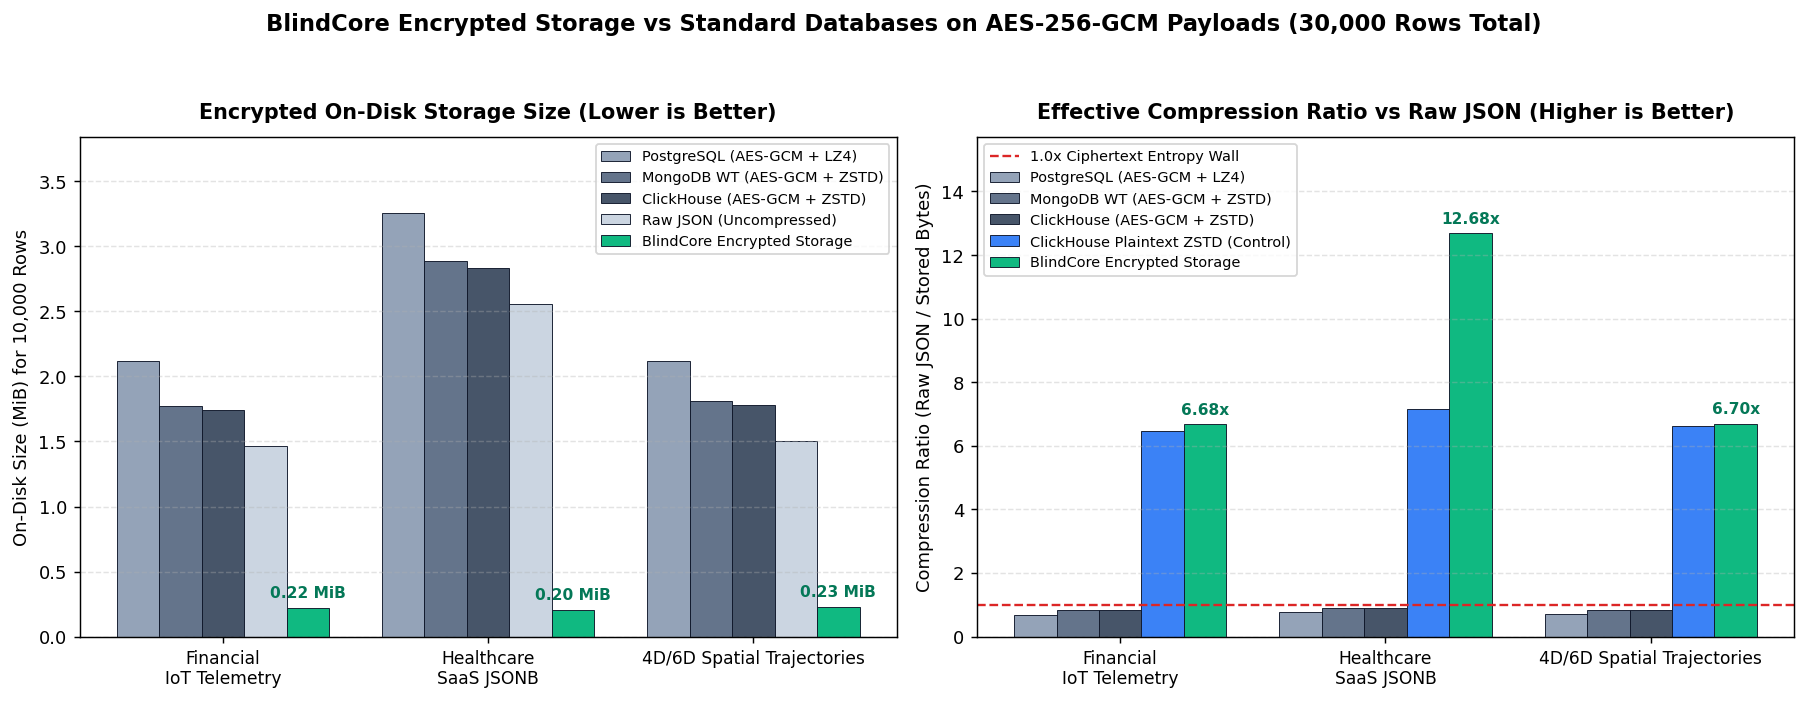

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.0, 5.4), dpi=130)
fig.patch.set_facecolor("white")

labels = [r["label"].replace(" / ", "\n") for r in summary_rows]
x = np.arange(len(labels))
w = 0.16

series_mb = [
    ("PostgreSQL (AES-GCM + LZ4)", [r["postgres_aes_lz4_bytes"] / (1024 * 1024) for r in summary_rows], "#94A3B8"),
    ("MongoDB WT (AES-GCM + ZSTD)", [r["mongodb_aes_zstd_bytes"] / (1024 * 1024) for r in summary_rows], "#64748B"),
    ("ClickHouse (AES-GCM + ZSTD)", [r["clickhouse_aes_zstd_bytes"] / (1024 * 1024) for r in summary_rows], "#475569"),
    ("Raw JSON (Uncompressed)", [r["raw_json_bytes"] / (1024 * 1024) for r in summary_rows], "#CBD5E1"),
    ("BlindCore Encrypted Storage", [r["blindcore_disk_encrypted_bytes"] / (1024 * 1024) for r in summary_rows], "#10B981"),
]

for idx_s, (sname, vals, col) in enumerate(series_mb):
    offset = (idx_s - 2.0) * w
    bars = ax1.bar(x + offset, vals, width=w, label=sname, color=col, edgecolor="#0F172A", linewidth=0.5)
    if sname == "BlindCore Encrypted Storage":
        for bar, v in zip(bars, vals):
            ax1.text(
                bar.get_x() + bar.get_width() / 2.0,
                v + 0.06,
                f"{v:.2f} MiB",
                ha="center",
                va="bottom",
                fontsize=8.5,
                fontweight="bold",
                color="#047857",
            )

ax1.set_title("Encrypted On-Disk Storage Size (Lower is Better)", fontsize=11.5, fontweight="bold", pad=10)
ax1.set_ylabel("On-Disk Size (MiB) for 10,000 Rows", fontsize=10)
ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=9.5)
ax1.set_ylim(0, max(r["postgres_aes_lz4_bytes"] for r in summary_rows) / (1024 * 1024) * 1.18)
ax1.grid(axis="y", linestyle="--", alpha=0.35)
ax1.legend(loc="upper right", fontsize=8.0, frameon=True)

# Right panel: Compression Ratio vs Raw JSON
ratio_series = [
    ("PostgreSQL (AES-GCM + LZ4)", [r["postgres_ratio_vs_raw"] for r in summary_rows], "#94A3B8"),
    ("MongoDB WT (AES-GCM + ZSTD)", [r["mongodb_zstd_ratio_vs_raw"] for r in summary_rows], "#64748B"),
    ("ClickHouse (AES-GCM + ZSTD)", [r["clickhouse_zstd_ratio_vs_raw"] for r in summary_rows], "#475569"),
    ("ClickHouse Plaintext ZSTD (Control)", [r["clickhouse_plaintext_ratio_vs_raw"] for r in summary_rows], "#3B82F6"),
    ("BlindCore Encrypted Storage", [r["blindcore_disk_ratio_vs_raw"] for r in summary_rows], "#10B981"),
]

for idx_s, (sname, vals, col) in enumerate(ratio_series):
    offset = (idx_s - 2.0) * w
    bars = ax2.bar(x + offset, vals, width=w, label=sname, color=col, edgecolor="#0F172A", linewidth=0.5)
    if sname == "BlindCore Encrypted Storage":
        for bar, v in zip(bars, vals):
            ax2.text(
                bar.get_x() + bar.get_width() / 2.0,
                v + 0.22,
                f"{v:.2f}x",
                ha="center",
                va="bottom",
                fontsize=8.5,
                fontweight="bold",
                color="#047857",
            )

ax2.axhline(1.0, color="#DC2626", linestyle="--", linewidth=1.3, label="1.0x Ciphertext Entropy Wall")
ax2.set_title("Effective Compression Ratio vs Raw JSON (Higher is Better)", fontsize=11.5, fontweight="bold", pad=10)
ax2.set_ylabel("Compression Ratio (Raw JSON / Stored Bytes)", fontsize=10)
ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=9.5)
ax2.set_ylim(0, max(r["blindcore_disk_ratio_vs_raw"] for r in summary_rows) * 1.24)
ax2.grid(axis="y", linestyle="--", alpha=0.35)
ax2.legend(loc="upper left", fontsize=8.0, frameon=True)

fig.suptitle(
    "BlindCore Encrypted Storage vs Standard Databases on AES-256-GCM Payloads (30,000 Rows Total)",
    fontsize=12.5,
    fontweight="bold",
    y=0.99,
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 5. Key Takeaways & Transparent Methodology Notes

1. **Why Standard Databases Expand Encrypted Data (`0.69x - 0.90x`):**  
   In PostgreSQL, MongoDB WiredTiger, and ClickHouse, client-side AES-256-GCM produces `7.9999 bits/byte` ciphertext entropy. Across all `30,000` rows, PostgreSQL TOAST `LZ4` compressed `0 / 30,000` rows, and ClickHouse `LZ4` and `ZSTD(1)` compressed `0` blocks -- collapsing identically to raw ciphertext + framing overhead. Yet on the *unencrypted* plaintext control, the exact same ClickHouse `ZSTD(1)` codec achieved `6.46x - 7.16x` compression, isolating ciphertext entropy as the sole cause of the collapse.
2. **Why App-Side Per-Row Compression Before AES-256-GCM Is Not Equivalent:**  
   Compressing individual `150 - 270 B` JSON rows in application code before AES-256-GCM misses cross-row columnar/dictionary correlation, leaks plaintext length side-channels (CRIME/BREACH class) unless fixed-bucket padded, and still leaves the database unable to run indexed queries or aggregates over the stored records.
3. **Conservative Accounting Favoring Standard Databases:**  
   The PostgreSQL, MongoDB WiredTiger, and ClickHouse totals above measure **raw table/collection data bytes only** (excluding B-tree/secondary indexes and WAL), and use ClickHouse's most-compact single-column encrypted `String` layout rather than per-column cell encryption. By contrast, BlindCore's primary on-disk encrypted storage metric **already includes** built-in column indexes, membership filters, dual-clock metadata, and authenticated AES-256-GCM sealing -- while still delivering **7.9x to 16.2x smaller encrypted storage** (`87.4%` to `93.8%` reduction) with `0` plaintext leaks on disk and exact SQL round-trip parity.